##  Tools and settings
We import libraries (ready-made toolboxes) and set a few values used later.

In [23]:
import os                                   # tools for folders and files
import numpy as np                          # NumPy: maths on lists of numbers
import pandas as pd                         # pandas: tables, like Excel inside Python
import matplotlib.pyplot as plt             # matplotlib: draws charts
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor   # our two ML models (forest of decision trees)
from sklearn.ensemble import HistGradientBoostingRegressor                   # another tree model; it can aim for the TYPICAL (median) answer
from sklearn.metrics import accuracy_score, mean_absolute_error              # scoring tools: % correct, average mistake size

DATA_DIR = "/mnt/user-data/uploads" if os.path.exists("/mnt/user-data/uploads") else "."  # folder with your CSVs ("." = same folder as this notebook)
SCHED_FILE = os.path.join(DATA_DIR, "scheduler_data[1].csv")   # full path to the job register file
DCGM_FILE  = os.path.join(DATA_DIR, "dcgm.csv")             # full path to the GPU meter file
OUT_DIR = "outputs"                         # folder name where we will save results
os.makedirs(OUT_DIR, exist_ok=True)         # create that folder (no error if it already exists)

START_DATE = pd.Timestamp("2021-01-01")     # PLACEHOLDER: time in the file is "seconds since start"; agree the real start date with your team!
UNLIMITED = 4294967295                      # the special number the scheduler uses to mean "no time limit"
SEED = 42                                   # fixed random seed so you get the same results every run

## Loading the file
* **scheduler_data**: the job register. One row = one job (what was requested, when).
* **dcgm**: the GPU meter. One row = one job on **one GPU** (what was actually used).

In [4]:
jobs = pd.read_csv(SCHED_FILE)              # read the job register CSV into a table called "jobs"
meter = pd.read_csv(DCGM_FILE)              # read the GPU meter CSV into a table called "meter"
print("jobs table  :", jobs.shape)          # shape = (number of rows, number of columns)
print("meter table :", meter.shape)         # same for the meter table
jobs.head(3)                                # show the first 3 rows so you can see what the data looks like

jobs table  : (287173, 31)
meter table : (96893, 23)


,id_array_job,id_array_task,id_user,kill_requid,nodes_alloc,nodelist,cpus_req,derived_ec,exit_code,gres_req,...,time_submit,time_eligible,time_start,time_end,time_suspended,track_steps,tres_alloc,tres_req,job_type,id_job
0,41161693674,4595979483,66088413977,51671871839,0,[],1,0,256,NaN,...,3014,3014,3014,3014,-1,0,NaN,"1=1,2=5000,4=1,5=1,1002=2",OTHER,13715936505
1,41161693674,4595979483,66088413977,51671871839,1,['r2684277-n303509'],1,0,0,gpu:volta:2,...,3022,3022,3022,3025,-1,0,"1=1,2=9600,4=1,5=1,1002=2","1=1,2=9600,4=1,5=1,1002=2",OTHER,25780056187
2,41161693674,4595979483,16176946191,51671871839,1,['r5198790-n347934'],4,32512,32512,gpu:volta:1,...,5682,5682,5683,5684,-1,0,"1=4,2=38400,4=1,5=4,1002=1","1=4,2=38400,4=1,5=4,1002=1",OTHER,53722449986


## cleaning data(data preprocessing) 

Real data is messy. We fix it in small steps and **print how many rows each step removes**, so you can explain every decision in your report.
**Step 1: remove duplicates.** If the same job ID appears twice, the job is counted twice, which is wrong.

In [5]:
rows_before = len(jobs)                                   # remember how many rows we start with
jobs = jobs.drop_duplicates("id_job", keep="last")        # if an id_job appears twice, keep only the last copy
print("duplicate jobs removed:", rows_before - len(jobs)) # print how many rows disappeared

duplicate jobs removed: 104


**Step 2: turn text into numbers.**
The GPU request is stored as text like `gpu:volta:2` (= 2 GPUs). CPUs and memory are hidden inside a text like `1=4,2=38400,4=1,...` where key `1` is CPUs and key `2` is memory in MB.
A model can only use numbers, so we pull the numbers out of the text.

*(We do not use the column `mem_req`. Its big numbers contain a special flag from the scheduler and are not real megabytes.)*

In [6]:
jobs["gpus"] = jobs["gres_req"].str.extract(r"(\d+)\s*$")[0]       # from text like "gpu:volta:2" take the number at the very end -> "2"
jobs["gpus"] = jobs["gpus"].astype(float).fillna(0)                # make it a real number; jobs with no GPU text (empty) become 0
jobs["cpus"] = jobs["tres_req"].str.extract(r"(?:^|,)1=(\d+)")[0].astype(float)     # find "1=<number>" in tres_req -> CPUs requested
jobs["mem_mb"] = jobs["tres_req"].str.extract(r"(?:^|,)2=(\d+)")[0].astype(float)   # find "2=<number>" in tres_req -> memory in MB
jobs[["gres_req", "gpus", "cpus", "mem_mb"]].head()                # show the original text next to the new numbers to check it worked

,gres_req,gpus,cpus,mem_mb
0,NaN,0.0,1.0,5000.0
1,gpu:volta:2,2.0,1.0,9600.0
2,gpu:volta:1,1.0,4.0,38400.0
3,gpu:volta:1,1.0,4.0,20000.0
4,gpu:volta:1,1.0,4.0,20000.0


**Step 3: fix "magic numbers".**
Some columns use special numbers instead of leaving a cell empty:
* `timelimit = 4294967295` means "unlimited" (not a real number of minutes).
* `time_start = -1` means "this job never started".
If we leave them, the model thinks "unlimited" is an absurdly large limit. So we mark them as missing (NaN) and keep a yes/no column to remember.

In [7]:
jobs["limit_unlimited"] = (jobs["timelimit"] == UNLIMITED).astype(int)          # 1 if the job had no time limit, else 0
real_limits = jobs.loc[jobs["timelimit"] != UNLIMITED, "timelimit"]             # all the time limits that are real numbers
jobs.loc[jobs["timelimit"] == UNLIMITED, "timelimit"] = real_limits.max()       # replace the magic number with the largest real limit
jobs.loc[jobs["time_start"] < 0, "time_start"] = np.nan                         # start time of -1 means "never started" -> mark as missing
jobs["runtime_s"] = jobs["time_end"] - jobs["time_start"]                       # runtime in seconds = end time minus start time
jobs.loc[jobs["runtime_s"] < 0, "runtime_s"] = np.nan                           # a negative runtime is impossible -> missing
jobs["is_array"] = (jobs["id_array_job"] != jobs["id_array_job"].mode()[0]).astype(int)  # most common array ID means "not an array job"; 1 = array job
print("jobs with a valid runtime:", jobs["runtime_s"].notna().sum(), "of", len(jobs))    # how many jobs actually have a usable runtime

jobs with a valid runtime: 217634 of 287069


**Step 4: remove rows we should not use.**

| Rows removed | Why |
|---|---|
| State 0, 1 or 1024 (still pending, still running, or restarted) | The job has not finished, so its record is incomplete |
| Partition `test` (5 rows) | A testing queue, not real work |
| Jobs with **no GPU** (`gpus == 0`) | CarbonSim only simulates GPU jobs, so these are not relevant to our project |
| Jobs asking for **more than 32 GPUs** | Extreme outliers (a few asked for hundreds). A handful of such rows can distort what the model learns |
| Rows where CPUs or memory could not be read | We cannot train on a row with a missing answer |

Jobs that **never started** are *kept* for now. They still made a request and still arrived, which is what blocks 5 to 7 need.

In [8]:
n = len(jobs)                                                         # row count before this step
jobs = jobs[~jobs["state"].isin([0, 1, 1024])]                        # keep rows whose state is NOT 0, 1 or 1024 (~ means "not")
print("removed unfinished jobs       :", n - len(jobs)); n = len(jobs) # print how many went, then update the counter
jobs = jobs[jobs["partition"] != "test"]                              # drop the 5 rows from the "test" partition
print("removed test-partition rows   :", n - len(jobs)); n = len(jobs)
jobs = jobs[jobs["gpus"] > 0]                                         # keep only jobs that asked for at least 1 GPU
print("removed jobs with no GPU      :", n - len(jobs)); n = len(jobs)
jobs = jobs[jobs["gpus"] <= 32]                                       # keep only jobs asking for 32 GPUs or fewer
print("removed jobs with > 32 GPUs   :", n - len(jobs)); n = len(jobs)
jobs = jobs.dropna(subset=["cpus", "mem_mb"])                         # drop rows where CPUs or memory is missing
print("removed rows with missing CPU/mem:", n - len(jobs))
print("FINAL number of GPU jobs      :", len(jobs))                   # how many rows we have left to work with

removed unfinished jobs       : 200
removed test-partition rows   : 5
removed jobs with no GPU      : 70482
removed jobs with > 32 GPUs   : 1184
removed rows with missing CPU/mem: 531
FINAL number of GPU jobs      : 214667


##  Create features
A model is only as good as the clues you give it. We create four kinds:

1. **Time clues**: hour of day, day of week, weekend or not.
2. **User history**: what this user asked for the *last* time. People repeat themselves, so this is the strongest clue.
3. **Job form details**: partition, job type, time limit, array job or not.
4. **System busyness**: how many jobs arrived in the previous hour.

We also take the **logarithm** of the targets. Most jobs are small and a few are enormous. The log squeezes the huge values so the model is not obsessed with them (10, 100, 1000 become 2.4, 4.6, 6.9).

In [9]:
jobs = jobs.sort_values("time_submit").reset_index(drop=True)          # sort jobs from oldest to newest, then renumber rows 0,1,2,...
jobs["when"] = START_DATE + pd.to_timedelta(jobs["time_submit"], unit="s")   # turn "seconds since start" into a real date and time
jobs["hour"] = jobs["when"].dt.hour                                    # hour of the day, 0 to 23
jobs["weekday"] = jobs["when"].dt.dayofweek                            # day of week, 0 = Monday ... 6 = Sunday
jobs["weekend"] = (jobs["weekday"] >= 5).astype(int)                   # 1 if Saturday or Sunday, else 0

jobs["log_gpus"] = np.log1p(jobs["gpus"])                              # log(1 + GPUs); the +1 avoids log(0) problems
jobs["log_cpus"] = np.log1p(jobs["cpus"])                              # same for CPUs
jobs["log_mem"] = np.log1p(jobs["mem_mb"])                             # same for memory
jobs["log_runtime"] = np.log1p(jobs["runtime_s"])                      # same for runtime (stays missing where runtime is missing)

In [10]:
by_user = jobs.groupby("id_user")                                      # treat each user's jobs as a separate group
for col in ["log_gpus", "log_cpus", "log_mem"]:                        # do the same thing for each of the three requests
    jobs["last_" + col] = by_user[col].shift(1)                        # shift(1) = value from the user's PREVIOUS job (never the job itself)
jobs["user_prev_jobs"] = by_user.cumcount()                            # how many jobs this user submitted before this one (0, 1, 2, ...)
jobs["has_history"] = (jobs["user_prev_jobs"] > 0).astype(int)         # 1 if the user has submitted before, 0 if this is their first job

for col in ["last_log_gpus", "last_log_cpus", "last_log_mem"]:         # first-time users have an empty "last request"
    jobs[col] = jobs[col].fillna(jobs[col].median())                   # fill the gap with the typical (median) value so the model can run

In [11]:
jobs["prev_end_time"] = jobs.groupby("id_user")["time_end"].shift(1)                  # when this user's PREVIOUS job ended
jobs["last_log_runtime"] = jobs.groupby("id_user")["log_runtime"].shift(1)            # how long the user's PREVIOUS job ran (log scale)
still_running = ~(jobs["prev_end_time"] <= jobs["time_submit"])                       # True if the previous job had NOT finished yet (or is unknown)
jobs.loc[still_running, "last_log_runtime"] = np.nan                                  # in that case we do not know its runtime yet -> mark as missing
jobs["has_prev_runtime"] = jobs["last_log_runtime"].notna().astype(int)               # 1 if a usable previous runtime exists, else 0
print("jobs with a usable previous-job runtime:", jobs["has_prev_runtime"].sum(), "of", len(jobs))   # how often this clue is available

jobs with a usable previous-job runtime: 35396 of 214667


In [12]:
jobs["hour_index"] = (jobs["time_submit"] // 3600).astype(int)         # which hour (since start) each job was submitted in (// = divide and drop decimals)
per_hour = jobs["hour_index"].value_counts().sort_index()              # count jobs per hour
per_hour = per_hour.reindex(range(per_hour.index.min(), per_hour.index.max() + 1), fill_value=0)  # add the hours with no jobs, as 0
prev_hour = per_hour.shift(1).rename("jobs_prev_hour")                 # shift(1) = use the PREVIOUS hour's count (we cannot know the current hour)
jobs = jobs.merge(prev_hour, left_on="hour_index", right_index=True, how="left")  # attach it to each job by hour number
jobs["jobs_prev_hour"] = jobs["jobs_prev_hour"].fillna(0)              # the very first hour has no previous hour -> use 0

jobs = pd.get_dummies(jobs, columns=["partition", "job_type", "constraints"], dtype=int)  # one-hot encoding: text category -> one 0/1 column per category

FEATURES = (["hour", "weekday", "weekend", "timelimit", "limit_unlimited", "is_array", "priority",
             "last_log_gpus", "last_log_cpus", "last_log_mem", "user_prev_jobs", "has_history", "jobs_prev_hour"]
            + [c for c in jobs.columns if c.startswith(("partition_", "job_type_", "constraints_"))])   # the list of columns the model may use as clues
FEATURES = [c for c in FEATURES if c in jobs.columns]                  # safety: keep only names that exist
jobs["timelimit"] = jobs["timelimit"].fillna(jobs["timelimit"].median())   # fill any leftover empty time limits with the median
print("number of features:", len(FEATURES))                            # how many clues the model gets
print(FEATURES)                                                        # show their names

number of features: 24
['hour', 'weekday', 'weekend', 'timelimit', 'limit_unlimited', 'is_array', 'priority', 'last_log_gpus', 'last_log_cpus', 'last_log_mem', 'user_prev_jobs', 'has_history', 'jobs_prev_hour', 'partition_gaia', 'partition_gpu', 'partition_normal', 'job_type_LLMAPREDUCE:MAP', 'job_type_LLSUB:BATCH', 'job_type_LLSUB:INTERACTIVE', 'job_type_OTHER', 'constraints_xeon-e5', 'constraints_xeon-e5&2680v4', 'constraints_xeon-g6', 'constraints_xeon-g6&6248']


##  Split into training and test sets (by time)
* **Training set** (first 80% of the timeline): the model studies this.
* **Test set** (last 20%): the "final exam". The model never sees it while learning.
We split **by time, not randomly**. In real life we predict the future from the past. A random split would let the model peek at jobs from the same week it is tested on, which makes the results look better than they really are.

In [13]:
cut = int(len(jobs) * 0.80)                                            # row number where the first 80% ends (jobs are already sorted by time)
train = jobs.iloc[:cut].copy()                                         # everything before the cut = training data
test = jobs.iloc[cut:].copy()                                          # everything after the cut = test data
print("train jobs:", len(train), "| ends on", train["when"].max().date())    # size and last date of the training part
print("test jobs :", len(test), "| starts on", test["when"].min().date())    # size and first date of the test part
top_user = jobs["id_user"].value_counts().index[0]                     # ID of the user who submitted the most jobs
print("top user's share of all jobs:", round((jobs["id_user"] == top_user).mean(), 3))   # how dominant that user is
not_top = (test["id_user"] != top_user).values                         # True/False list: test jobs NOT from that top user (used for a fairness check)

train jobs: 171733 | ends on 2021-10-08
test jobs : 42934 | starts on 2021-10-08
top user's share of all jobs: 0.466


##  Predicting the number of GPUs
GPU count is a **category** (nobody asks for 2.7 GPUs), so this is a **classification** problem. We group GPUs into 5 classes: **1, 2, 3-4, 5-8, 9+**.

**Baseline** (the simple guess we must beat): *"the user will ask for the same as last time."*
**Model:** a **Random Forest**: many decision trees, each asking yes/no questions like "was the last request more than 2 GPUs?". The forest takes a vote. Many simple trees voting is more reliable than one tree.

In [14]:
def gpu_class(g):                                                      # a small function that turns a GPU count into a class number
    return np.select([g <= 1, g <= 2, g <= 4, g <= 8], [0, 1, 2, 3], default=4)   # <=1 -> class 0, <=2 -> 1, <=4 -> 2, <=8 -> 3, else 4
CLASS_NAMES = ["1", "2", "3-4", "5-8", "9+"]                           # human-readable names for classes 0..4
train["gpu_class"] = gpu_class(train["gpus"])                          # the correct answer for each training job
test["gpu_class"] = gpu_class(test["gpus"])                            # the correct answer for each test job (used only for grading)

baseline_pred = gpu_class(np.expm1(test["last_log_gpus"]))             # baseline: convert the log back to real GPUs, then to a class
forest = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,  # 100 trees; each leaf must hold at least 5 jobs (avoids memorising)
                                class_weight="balanced",               # give rare classes (many GPUs) more importance
                                n_jobs=-1, random_state=SEED)          # use all CPU cores; fixed seed for repeatable results
forest.fit(train[FEATURES], train["gpu_class"])                        # LEARN: show the model the training clues and the correct answers
model_pred = forest.predict(test[FEATURES])                            # PREDICT: guess the classes for the unseen test jobs

print("Baseline accuracy (all test jobs)      :", round(accuracy_score(test["gpu_class"], baseline_pred), 3))   # % of test jobs the baseline got right
print("Random Forest accuracy (all test jobs) :", round(accuracy_score(test["gpu_class"], model_pred), 3))      # % the forest got right
print("Baseline accuracy (without top user)   :", round(accuracy_score(test["gpu_class"][not_top], baseline_pred[not_top]), 3))   # fairness check
print("Forest accuracy (without top user)     :", round(accuracy_score(test["gpu_class"][not_top], model_pred[not_top]), 3))       # fairness check

Baseline accuracy (all test jobs)      : 0.875
Random Forest accuracy (all test jobs) : 0.961
Baseline accuracy (without top user)   : 0.871
Forest accuracy (without top user)     : 0.96


In [15]:
confusion = pd.crosstab(pd.Series(test["gpu_class"].values, name="TRUE").map(dict(enumerate(CLASS_NAMES))),   # rows = what the job really asked for
                        pd.Series(model_pred, name="PREDICTED").map(dict(enumerate(CLASS_NAMES))))            # columns = what the model guessed
confusion                                                                                                      # the diagonal = correct guesses

PREDICTED,1,2,3-4,5-8,9+
TRUE,,,,,
1,36480,945,13,112,7
2,287,4372,60,34,8
3-4,18,51,122,7,6
5-8,9,70,9,77,24
9+,3,7,3,5,205


## Predict CPUs and memory
These are **numbers**, so this is **regression**. We predict the log value and convert back at the end.

**Scoring:**
* **MAE** (Mean Absolute Error): the average size of the mistake. Smaller is better.
* **Under-prediction rate**: how often we guessed *less* than the job really asked for. This matters because too little memory makes a job crash, so this is the dangerous mistake.

We compare against the same simple baseline: "same as the user's last request".

In [16]:
def score(name, true_log, pred_log):                                   # a helper that prints the scores for one set of predictions
    true_real = np.expm1(true_log)                                     # convert the true values from log scale back to real units
    pred_real = np.expm1(np.clip(pred_log, 0, None))                   # convert predictions back; clip stops negative guesses
    mae = mean_absolute_error(true_real, pred_real)                    # average size of the mistake in real units
    under = (pred_real < true_real - 1e-9).mean()                      # share of jobs where we guessed too LOW
    print(f"{name:<34} average mistake = {mae:>10.1f}   guessed too low = {under:.1%}")   # print one neat line of results

results = {}                                                           # a dictionary to keep predictions for saving later
for label, target, last_col in [("CPUs", "log_cpus", "last_log_cpus"), ("Memory (MB)", "log_mem", "last_log_mem")]:  # do the same for CPUs, then memory
    print("-----", label, "-----")                                    # heading for this target
    score("Baseline (user's last request)", test[target], test[last_col])   # score the simple baseline
    reg = RandomForestRegressor(n_estimators=100, min_samples_leaf=5,  # a forest of 100 trees, each leaf holding at least 5 jobs
                                n_jobs=-1, random_state=SEED)          # all CPU cores, repeatable
    reg.fit(train[FEATURES], train[target])                            # LEARN from the training jobs
    pred = reg.predict(test[FEATURES])                                 # PREDICT for the test jobs
    score("Random Forest", test[target], pred)                         # score the forest
    change = train[target] - train[last_col]                           # NEW IDEA: instead of the value itself, learn the CHANGE from the user's last request
    reg2 = HistGradientBoostingRegressor(loss="absolute_error",        # aim for the TYPICAL change (median) so rare huge jumps do not drag it around
                                         max_iter=200, random_state=SEED)   # build up to 200 small trees, one correcting the previous; repeatable
    reg2.fit(train[FEATURES], change)                                  # LEARN the typical change (mostly 0 = "same as last time")
    pred2 = test[last_col] + reg2.predict(test[FEATURES])              # final guess = last request + predicted change
    score("Boosted trees predicting the CHANGE", test[target], pred2)         # score this second approach
    results[label] = np.expm1(np.clip(pred2, 0, None))                 # keep THIS version's predictions (real units) for saving

----- CPUs -----
Baseline (user's last request)     average mistake =        1.1   guessed too low = 2.2%
Random Forest                      average mistake =        3.4   guessed too low = 28.1%
Boosted trees predicting the CHANGE average mistake =        1.6   guessed too low = 3.0%
----- Memory (MB) -----
Baseline (user's last request)     average mistake =     9675.6   guessed too low = 2.3%
Random Forest                      average mistake =    28268.5   guessed too low = 34.4%
Boosted trees predicting the CHANGE average mistake =    11927.8   guessed too low = 14.4%


## Predict job runtime (how long a job runs)
**Why this matters:** a carbon-aware scheduler must know how long a job will occupy a GPU. If it knows a job runs for 8 hours it can place it in a green period; if it runs for 2 minutes, waiting is pointless. Runtime is also needed to turn power into energy (energy = power x time).

**Where the runtime comes from:** the **scheduler file** (`jobs`). Runtime = `time_end - time_start` (The GPU meter file also has a runtime, but covers only about a third of the jobs.)

**Which rows are used:** only jobs that really **started and finished** (a valid runtime). Jobs that never started are removed *for this task only*; they stay in all other tasks.

**Clues (features) allowed:** everything known at submit time. New here: the job's **own** request (GPUs, CPUs, memory). A job asking for 8 GPUs probably runs differently from one asking for 1, and the user has stated this on the form. Plus the user's previous runtime (if it had finished).

**Baselines to beat:** (a) the typical runtime of all jobs, (b) the same runtime as the user's previous job.

**How we score it:** runtime is predicted on the **log scale**, so the average mistake `m` means "off by a factor of about e^m". For example m = 0.7 means roughly 2x too high or too low. We also show how often we guess **too short** (dangerous for a scheduler) and whether we pick the right **time bucket** (under 1 min, 1-10 min, 10-60 min, 1-6 h, over 6 h).

In [17]:
rt_features = FEATURES + ["log_gpus", "log_cpus", "log_mem", "last_log_runtime", "has_prev_runtime"]   # the usual clues PLUS the job's own request and previous runtime
train_rt = train[train["log_runtime"].notna()].copy()                  # training jobs that have a valid runtime
test_rt = test[test["log_runtime"].notna()].copy()                     # test jobs that have a valid runtime
print("jobs used for runtime  -> train:", len(train_rt), "| test:", len(test_rt))   # how many jobs this task uses
median_rt = train_rt["log_runtime"].median()                           # the typical (median) log-runtime of the TRAINING jobs
for part in (train_rt, test_rt):                                       # fill the gaps in both parts the same way
    part["last_log_runtime"] = part["last_log_runtime"].fillna(median_rt)   # no usable previous runtime -> use the typical value
not_top_rt = (test_rt["id_user"] != top_user).values                   # True/False list: test jobs NOT from the dominant user

jobs used for runtime  -> train: 171715 | test: 42925


In [18]:
def score_runtime(name, true_log, pred_log, mask=None):                # helper that prints the scores for one set of runtime predictions
    if mask is not None:                                               # optional: only score some jobs (e.g. without the top user)
        true_log, pred_log = true_log[mask], pred_log[mask]            # keep only those jobs
    pred_log = np.clip(pred_log, 0, None)                              # runtime cannot be negative
    mae_log = mean_absolute_error(true_log, pred_log)                  # average mistake on the log scale (smaller is better)
    mae_min = mean_absolute_error(np.expm1(true_log), np.expm1(pred_log)) / 60   # average mistake in real MINUTES (dominated by long jobs)
    too_short = (np.expm1(pred_log) < np.expm1(true_log) * 0.9).mean() # share of jobs where we guessed clearly SHORTER (more than 10% too short)
    print(f"{name:<40} log-mistake = {mae_log:.2f} (about x{np.exp(mae_log):.1f})   mistake = {mae_min:7.1f} min   guessed too short = {too_short:.1%}")   # one neat line

y_true = test_rt["log_runtime"].values                                 # the real log-runtimes of the test jobs (answers, for grading only)
pred_median = np.full(len(test_rt), median_rt)                         # baseline (a): everyone gets the typical runtime
pred_last = test_rt["last_log_runtime"].values                         # baseline (b): same as the user's previous job
score_runtime("Baseline: typical runtime of all jobs", y_true, pred_median)       # score baseline (a)
score_runtime("Baseline: user's previous job runtime", y_true, pred_last)         # score baseline (b)

rt_forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED)   # a forest of 100 trees
rt_forest.fit(train_rt[rt_features], train_rt["log_runtime"])          # LEARN: training clues -> training runtimes
pred_forest = rt_forest.predict(test_rt[rt_features])                  # PREDICT runtimes for the unseen test jobs
score_runtime("Random Forest", y_true, pred_forest)                    # score the forest

rt_boost = HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, random_state=SEED)   # boosted trees aiming for the TYPICAL (median) runtime
rt_boost.fit(train_rt[rt_features], train_rt["log_runtime"])           # LEARN from the training jobs
pred_boost = rt_boost.predict(test_rt[rt_features])                    # PREDICT for the test jobs
score_runtime("Boosted trees (median-targeting)", y_true, pred_boost)  # score the boosted model
print()                                                                # blank line
score_runtime("Baseline (user's previous), no top user", y_true, pred_last, not_top_rt)   # fairness check: same baseline without the dominant user
score_runtime("Random Forest, no top user", y_true, pred_forest, not_top_rt)              # fairness check for the forest
score_runtime("Boosted trees, no top user", y_true, pred_boost, not_top_rt)               # fairness check for boosted trees

Baseline: typical runtime of all jobs    log-mistake = 3.19 (about x24.2)   mistake =   367.9 min   guessed too short = 65.5%
Baseline: user's previous job runtime    log-mistake = 3.03 (about x20.8)   mistake =   371.4 min   guessed too short = 63.0%
Random Forest                            log-mistake = 2.71 (about x15.0)   mistake =   372.5 min   guessed too short = 43.4%
Boosted trees (median-targeting)         log-mistake = 2.62 (about x13.8)   mistake =   365.0 min   guessed too short = 42.7%

Baseline (user's previous), no top user  log-mistake = 3.09 (about x21.9)   mistake =   379.7 min   guessed too short = 63.7%
Random Forest, no top user               log-mistake = 2.75 (about x15.7)   mistake =   381.4 min   guessed too short = 43.0%
Boosted trees, no top user               log-mistake = 2.65 (about x14.1)   mistake =   373.6 min   guessed too short = 41.8%


In [35]:
bins = [-np.inf, 60, 600, 3600, 6 * 3600, np.inf]                      # bucket edges in seconds: 1 min, 10 min, 1 hour, 6 hours
names = ["<1 min", "1-10 min", "10-60 min", "1-6 h", ">6 h"]           # readable bucket names
def to_bucket(log_runtime):                                            # helper: log-runtime -> bucket name
    return pd.cut(np.expm1(np.clip(log_runtime, 0, None)), bins=bins, labels=names)   # convert back to seconds, then sort into a bucket
true_bucket = to_bucket(y_true)                                        # the real bucket of each test job
for label, p in [("Baseline: user's previous job", pred_last), ("Random Forest", pred_forest), ("Boosted trees", pred_boost)]:   # compare the three
    print(f"{label:<32} picks the right time bucket for {(to_bucket(p) == true_bucket).mean():.1%} of jobs")   # share of exactly-right buckets
pd.crosstab(pd.Series(true_bucket, name="TRUE bucket"), pd.Series(to_bucket(pred_boost), name="PREDICTED bucket (boosted)"))   # confusion table: diagonal = correct

Baseline: user's previous job    picks the right time bucket for 25.3% of jobs
Random Forest                    picks the right time bucket for 23.5% of jobs
Boosted trees                    picks the right time bucket for 26.1% of jobs


PREDICTED bucket (boosted),<1 min,1-10 min,10-60 min,1-6 h,>6 h
TRUE bucket,,,,,
<1 min,2176,4489,2914,2077,53
1-10 min,1367,2313,2731,2480,62
10-60 min,177,1280,4117,2040,42
1-6 h,217,930,3073,2189,111
>6 h,292,1256,3033,3115,391


##  Predict how many jobs arrive per hour
The scheduler needs to know how busy the next hours will be.

**Step 1.** Count jobs per hour. A problem: some users launch hundreds of jobs in one minute with a script. That is one *decision* by a human but hundreds of rows. So we also count **distinct submissions**: jobs from the same user in the same minute count as one.

**Step 2.** Give the model *lag features*, meaning the counts from earlier hours: 1 hour ago, 24 hours ago (same time yesterday), 168 hours ago (same time last week), and the average of the last 24 hours.

**Baseline:** the average of the last 24 hours.

In [20]:
def hourly_counts(times):                                              # a helper: list of submission times -> jobs per hour
    hr = (times // 3600).astype(int)                                   # which hour each submission falls in
    counts = hr.value_counts().sort_index()                            # count submissions per hour
    return counts.reindex(range(counts.index.min(), counts.index.max() + 1), fill_value=0).astype(float)   # add empty hours as 0

raw_counts = hourly_counts(jobs["time_submit"])                        # every job counts
one_per_minute = jobs.assign(minute=jobs["time_submit"] // 60).drop_duplicates(["id_user", "minute"])   # keep one job per user per minute
distinct_counts = hourly_counts(one_per_minute["time_submit"])         # count those distinct submissions per hour
print("hours in the data      :", len(raw_counts))                     # how long the timeline is, in hours
print("hours with zero jobs   :", int((raw_counts == 0).sum()))        # how many hours were completely empty
print("average jobs/hour (raw):", round(raw_counts.mean(), 1), "| distinct:", round(distinct_counts.mean(), 1))   # bursts make "raw" much bigger

hours in the data      : 8890
hours with zero jobs   : 2098
average jobs/hour (raw): 24.1 | distinct: 5.4


In [21]:
def forecast_hourly(counts, label):                                    # helper: build lag features, train a forest, compare with the baseline
    t = pd.DataFrame({"jobs": counts})                                 # a table whose column "jobs" is the hourly count
    t["lag_1h"] = counts.shift(1)                                      # count 1 hour ago
    t["lag_2h"] = counts.shift(2)                                      # count 2 hours ago
    t["lag_24h"] = counts.shift(24)                                    # count at the same time yesterday
    t["lag_168h"] = counts.shift(168)                                  # count at the same time last week
    t["avg_last_24h"] = counts.shift(1).rolling(24).mean()             # average of the previous 24 hours
    clock = START_DATE + pd.to_timedelta(t.index * 3600, unit="s")     # real clock time of each hour
    t["hour"] = clock.hour                                             # hour of day
    t["weekday"] = clock.dayofweek                                     # day of week
    t = t.dropna()                                                     # drop the first rows that do not have enough history for the lags
    split = int(len(t) * 0.80)                                         # first 80% of hours for training, last 20% for testing
    tr, te = t.iloc[:split], t.iloc[split:]                            # the two parts
    cols = [c for c in t.columns if c != "jobs"]                       # all columns except the answer are clues
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED)   # a forest for counts
    rf.fit(tr[cols], tr["jobs"])                                       # learn from the training hours
    guesses = {"Baseline: average of last 24 hours": te["avg_last_24h"],         # method 1: moving average
               "Baseline: same hour yesterday": te["lag_24h"],                    # method 2: copy yesterday
               "Random Forest with lags": pd.Series(rf.predict(te[cols]), index=te.index)}   # method 3: the forest
    print("-----", label, "-----")                                     # heading
    for name, g in guesses.items():                                    # score each method
        print(f"{name:<38} average mistake = {mean_absolute_error(te['jobs'], g):.2f} jobs/hour")   # smaller is better
    return te, guesses                                                 # give back the test part and the guesses (for plotting)

te_raw, g_raw = forecast_hourly(raw_counts, "RAW job count per hour")                     # forecast using every job
te_dist, g_dist = forecast_hourly(distinct_counts, "DISTINCT submissions per hour")       # forecast using one-per-minute counts

----- RAW job count per hour -----
Baseline: average of last 24 hours     average mistake = 24.54 jobs/hour
Baseline: same hour yesterday          average mistake = 28.81 jobs/hour
Random Forest with lags                average mistake = 26.41 jobs/hour
----- DISTINCT submissions per hour -----
Baseline: average of last 24 hours     average mistake = 4.27 jobs/hour
Baseline: same hour yesterday          average mistake = 4.74 jobs/hour
Random Forest with lags                average mistake = 3.60 jobs/hour


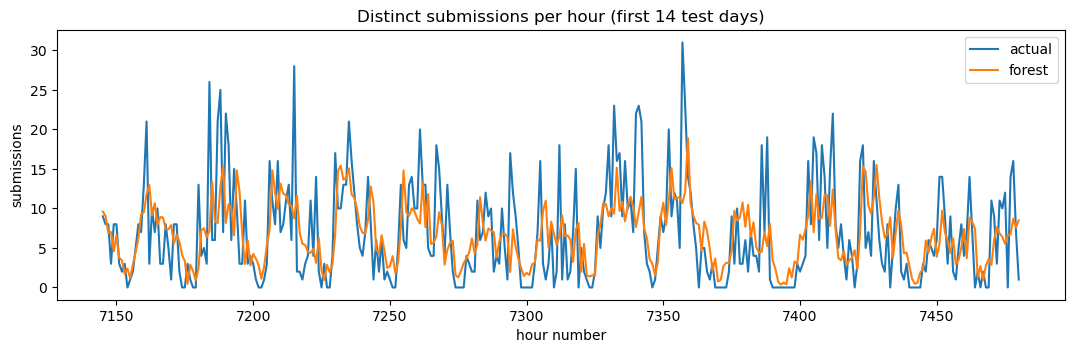

In [22]:
plt.figure(figsize=(13, 3.5))                                          # make an empty chart, 13 wide by 3.5 tall
first_two_weeks = te_dist.index[:24 * 14]                              # take the first 14 days (24 hours each) of the test period
plt.plot(first_two_weeks, te_dist.loc[first_two_weeks, "jobs"], label="actual")                    # the real counts
plt.plot(first_two_weeks, g_dist["Random Forest with lags"].loc[first_two_weeks], label="forest")  # the forest's guesses
plt.title("Distinct submissions per hour (first 14 test days)")        # chart title
plt.xlabel("hour number"); plt.ylabel("submissions"); plt.legend()     # axis labels and a legend
plt.show()                                                             # draw the chart